# HYSPLIT Ensembles Post-Processing Notebook

In [25]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
from global_land_mask import globe
import matplotlib.dates as mdates
import py_funcs as mask
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D


# Loading Data

In [2]:
# loading trajectory data
ens = xr.open_dataset('ensemble_data.nc')
ens = ens.compute()

In [3]:
# loading sea-ice data from University of Bremmen
ice_dum = xr.open_dataset('ice_data.nc')

# formatting so that it has the same time dimension as trajectory data
ice_dum = ice_dum.sel(time=slice('2023-05-08','2023-06-13'))
start, end = ice_dum.time.values[0], ice_dum.time.values[-1] + pd.Timedelta(hours=23)
hourly_times = pd.date_range(start, end, freq="1h")

# expand the time index from daily to hourly, simply repeating the values that are stored daily.
ice = ice_dum.reindex(time=hourly_times, method="ffill")
ice = ice.drop_sel(time='2023-05-24 01:00:00') 
ice = ice.rename({'time':'launch_time'})

# Applying the Masks

In [4]:
# first convert lat and lon coords of trajectory location to Polar Stereographic projection used by the Bremmen University for their ice data:
kw = dict(central_latitude=90, central_longitude=-45, true_scale_latitude=70)
projection = ccrs.Stereographic(**kw, false_easting= 0.0, false_northing=0.0, globe=None)

lon = ens['lon'].values
lat = ens['lat'].values

# projection the University of Bremen sea-ice data is stored in
coords = projection.transform_points(ccrs.PlateCarree(), lon.ravel(), lat.ravel())  

ens['x_stereo'] = (['launch_time', 'traj_step', 'ens_member'], coords[:, 0].reshape(lon.shape))
ens['y_stereo'] = (['launch_time', 'traj_step', 'ens_member'], coords[:, 1].reshape(lon.shape))

In [5]:
# find the closest sea-ice coordinate to each trajectory coordinate, slightly slow ~ 20 seconds.

closest_x = xr.apply_ufunc(
    mask.closest_icecoord,
    ens['x_stereo'],                        
    kwargs={"search_array": ice_dum.x.values},
    vectorize=True,                
    dask="parallelized",           
    output_dtypes=[ice_dum.x.values.dtype],
)

closest_y = xr.apply_ufunc(
    mask.closest_icecoord,
    ens['y_stereo'],
    kwargs={"search_array": ice_dum.y.values},
    vectorize=True,
    dask='parallelized',
    output_dtypes=[ice_dum.y.values.dtype],
)

ens['closest_x'] = closest_x
ens['closest_y'] = closest_y

In [6]:
# selecting the closest ice percentage for that trajectory coordinate location and time
z = ice['z'].sel(x=ens['closest_x'], y=ens['closest_y'])
ens['z'] = z
ens = ens.drop_vars(['x','y'])

In [7]:
# applying the ice mask, quite slow ~ 2 mins
ens['icemask'] = mask.ice_mask(ens['closest_x'], ens['closest_y'], ens['z'], 75)

In [8]:
# applying the land-ocean mask, quite slow ~ 2 mins 22 secs
landmask = xr.apply_ufunc(
    mask.land_mask,
    ens['lat'],
    ens['lon'],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[int],
)

ens['landmask'] = landmask

In [9]:
# applying the boundary layer mask (should happen last, if it is above the boundary layer we don't care what surface type it is over)
blmask = mask.bl_mask(ens['alt'], ens['bl_height'])
ens['blmask'] = blmask

In [10]:
# imposting heirarchy of booleans (making sure that there are no overlapping 1s or 0s) (first BL, then ice, then land, then ocean)

ens['icemask'] = xr.where(ens['blmask'] == 1, 0, ens['icemask']) # if above boundary layer return 0
ens['landmask'] = xr.where((ens['icemask'] == 1) | (ens['blmask'] == 1), 0, ens['landmask']) # if above boundary layer or determined as ice, return 0
ens['seamask'] = xr.where((ens['landmask']==0) & (ens['icemask']==0) & (ens['blmask'] == 0), 1, 0) # everything else is ocean

In [11]:
# checking the mask has only 1 1 and everything else is zero:
((ens['blmask'] + ens['icemask'] + ens['landmask'] + ens['seamask']) == 1).all()

<xarray.DataArray ()> Size: 1B
array(True)

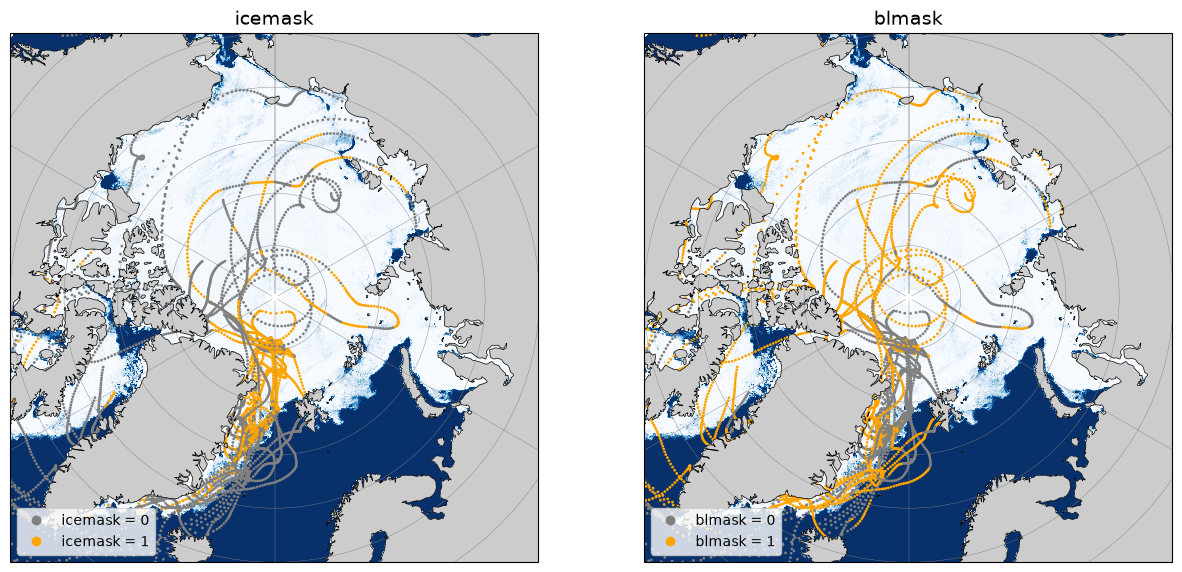

In [ ]:
# plotting ice and ice mask to sense-check code:

kw = dict(central_latitude=90, central_longitude=-45, true_scale_latitude=70)
projection = ccrs.Stereographic(**kw, false_easting= 0.0, false_northing=0.0, globe=None)
time = '2023-05-22 12:00:00'
mask_list = ['icemask','blmask']
mask_colours = ['grey', 'orange']

fig, axs = plt.subplots(1, 2, figsize=(15, 7), subplot_kw={"projection": ccrs.NorthPolarStereo()})
for ax, m in zip(axs, mask_list):
    ax.set_extent([-180, 180, 65, 90], crs=ccrs.PlateCarree()) 
    ax.add_feature(cfeature.LAND, facecolor="0.8", zorder=2)
    ax.coastlines(resolution="50m", linewidth=0.5, zorder=3)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="grey")

    #plot ice
    ice_plot = ax.pcolormesh(ice.x, ice.y, ice['z'].sel(launch_time=time), transform=projection, cmap="Blues_r", vmin=0, vmax=100, shading="auto")

    #plot ensemble
    ax.scatter(ens['lon'].sel(launch_time=time), ens['lat'].sel(launch_time=time), c=ens[m].sel(launch_time=time), cmap=ListedColormap(mask_colours), s=1, transform=ccrs.PlateCarree())
    ax.set_title(m, fontsize=14)

    # legend for the mask
    handles = [Line2D([], [], marker='o', linestyle='', color=mask_colours[0], label=f'{m} = 0'),
               Line2D([], [], marker='o', linestyle='', color=mask_colours[1], label=f'{m} = 1')]
    ax.legend(handles=handles, loc='lower left')
    ax.set_title(m, fontsize=14)

# Calculating and plotting the contributions from different surface types

In [31]:
traj_length = 7 # how many days back in time you want to obtain the statistics for

In [32]:
# recreating the contribution over time for the different surface types to the ensemble of back trajectories:
contributions = xr.Dataset(coords={'launch_time':ens.sel(traj_step=slice(0, 24*traj_length)).launch_time})
surf = ['land', 'ice', 'sea', 'bl']
for s in surf:
    mask = f'{s}mask'
    total = (traj_length*24 + 1) * 27 # (time steps * ensemble members)
    contributions[f'{s}_%'] = ( ens[mask].sel(traj_step = slice(0, 24*traj_length)).sum(dim=['ens_member', 'traj_step']) / total )*100
ens['mean_precip'] = ens['precip'].mean(dim='ens_member')
contributions['precip_mm/hr'] = ens['mean_precip'].sel(traj_step=slice(0, 24*traj_length)).sum(dim='traj_step')

In [33]:
# checking that the contributions sum to 100 % per back trajectory launch time
contributions['total'] = contributions['land_%'] + contributions['ice_%'] + contributions['sea_%'] + contributions['bl_%']
mask = ~np.isclose(contributions['total'], 100) 
np.sum(mask)

np.int64(0)

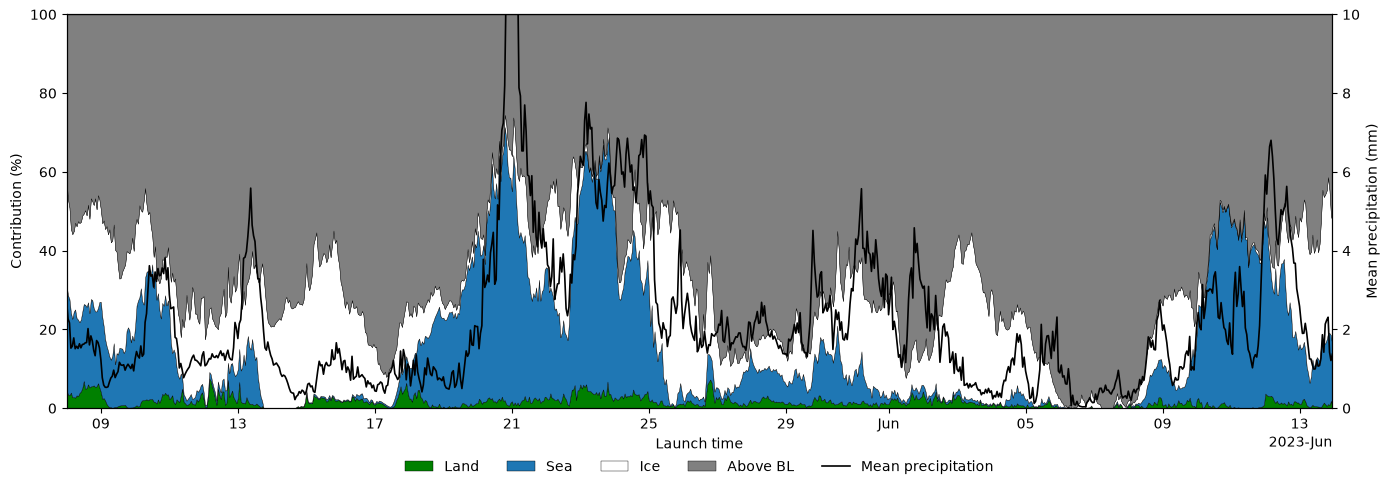

In [34]:
# plotting, claude wrote this code block.

layers = [           
    ("land_%", "Land",     "green"),
    ("sea_%",  "Sea",      "tab:blue"),
    ("ice_%",  "Ice",      "white"),
    ("bl_%",   "Above BL", "grey"),
]

times = contributions["launch_time"].values

fig, ax = plt.subplots(figsize=(14, 5))

ax.stackplot(
    times,
    *[contributions[var].values for var, _, _ in layers],
    labels=[label for _, label, _ in layers],
    colors=[colour for _, _, colour in layers],
    edgecolor="black",
    linewidth=0.3,
)

ax.set_xlim(times[0], times[-1])
ax.set_ylim(0, 100)
ax.set_ylabel("Contribution (%)")
ax.set_xlabel("Launch time")

# Precipitation on a second y-axis
ax2 = ax.twinx()
ax2.plot(times, contributions["precip_mm/hr"].values,
         color="black", linewidth=1.2, label="Mean precipitation")
ax2.set_ylabel("Mean precipitation (mm)")   # change units to match your data
ax2.set_ylim(0, 10)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

handles = handles1 + handles2
labels = labels1 + labels2
ax.legend(handles, labels,
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(labels), frameon=False)

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.tight_layout()
plt.show()

In [35]:
# saving data as a csv overview:
contributions.drop_vars('total').to_dataframe().to_csv('ens_7days_recent.csv')

# Adding metadata and formatting NetCDF File

In [36]:
ens = ens.drop_vars(['mean_precip','x_stereo','y_stereo','closest_x','closest_y'])
ens = ens.rename_vars({'z':'seaice_conc'})

In [56]:
ens.attrs["Title"] = "Ensembles of HYSPLIT back-trajectories for the ARTofMELT 2023 Expedition"
ens.attrs["Source"] = (
    "Trajectories: HYSPLIT v5.2.1 (NOAA ARL) ensemble back trajectories driven by GDAS 1-degree meteorology. "
    "Sea ice mask: University of Bremen AMSR2 ASI sea ice concentration v5.4, 6.25 km Polar Stereographic grid."
    "Land mask: global-land-mask Python package."
)
ens.attrs["References"] = (
    "Stein et al. (2015), BAMS, doi:10.1175/BAMS-D-14-00110.1; "
    "Rolph et al. (2017), Environ. Model. Softw., doi:10.1016/j.envsoft.2017.06.025; "
    "Spreen et al. (2008), J. Geophys. Res., doi:10.1029/2005JC003384; "
    "sea ice data from https://data.seaice.uni-bremen.de/amsr2/asi_daygrid_swath/n6250/ (accessed December 2023)"
)
ens.attrs["Created By"] = "Jessica Matthew"
ens.attrs["Comment"] = (
    "Each trajectory point is assigned to exactly one surface category, in priority order: "
    "above boundary layer > sea ice > land > sea. "
    "Sea ice where concentration >= 75%, or where data is missing within 325 km of the pole (satellite pole hole)."
    "See https://github.com/jessicacbm/ARTOFMELT2023_trajectory_masking GitHub repository for code and further information."
)
ens.attrs["Time Coverage Start"] = "08-05-2023 00:00:00"
ens.attrs["Time Coverage End"] = "13-06-2023 23:00:00"

In [57]:
var_attrs = {
    # Coordinates / dimensions
    "launch_time": {"long_name": "Ensemble launch time (UTC)"},
    "traj_step": {"long_name": "Hours back along trajectory from launch", "units": "hours"},
    "ens_member": {"long_name": "HYSPLIT ensemble member number", "units": "1"},
    "traj_time": {"long_name": "Time at the location of the air parcel (UTC)"},

    # HYSPLIT output
    "lat": {"standard_name": "Latitude", "long_name": "Air parcel latitude", "units": "degrees_north"},
    "lon": {"standard_name": "Longitude", "long_name": "Air parcel longitude", "units": "degrees_east"},
    "alt": {"standard_name": "Altitude", "long_name": "Air parcel height above ground level", "units": "m"},
    "pressure": {"long_name": "Air pressure at air parcel location", "units": "hPa"},
    "bl_height": {"long_name": "Planetary boundary layer height at air parcel location", "units": "m"},
    "pot_temp": {"long_name": "Potential temperature of air parcel", "units": "K"},
    "temp": {"long_name": "Temperature of air parcel", "units": "K"},
    "precip": {"long_name": "(Surface) precipitation rate at air parcel location", "units": "mm / hr"},
    "relhumid": {"long_name": "Relative humidity of air parcel", "units": "%"},
    "spchumid": {"long_name": "Specific humidity of air parcel", "units": "g kg-1"},
    "terr_msl": {"long_name": "Terrain height above mean sea level below air parcel", "units": "m"},
    "sun_flux": {"long_name": "Downward solar radiation flux at the surface below air parcel", "units": "W m-2"},

    # Sea ice
    "seaice_conc": {"long_name": "AMSR2 ASI sea ice concentration at the nearest grid cell", "units": "%",
                    "comments": "Ice data interpolated from University of Bremen sea-ice data contained on Polar Stereographic grid"},
    
    # Masks
    "blmask": {"long_name": "Above boundary layer mask", "units": "1",
               "flag_values": [0, 1], "flag_meanings": "within_boundary_layer above_boundary_layer",
               "comment": "1 where parcel height > boundary layer depth"},
    "icemask": {"long_name": "Sea ice surface mask", "units": "1",
                "flag_values": [0, 1], "flag_meanings": "not_ice ice",
                "comment": "1 where sea ice concentration >= 75%, or missing within 325 km of the pole, "
                           "0 where blmask = 1"},
    "landmask": {"long_name": "Land surface mask", "units": "1",
                 "flag_values": [0, 1], "flag_meanings": "not_land land",
                 "comment": "1 where global-land-mask attributes to land, 0 where blmask = 1 or icemask = 1"},
    "seamask": {"long_name": "Open sea surface mask", "units": "1",
                "flag_values": [0, 1], "flag_meanings": "not_sea sea",
                "comment": "1 where blmask, icemask and landmask are all 0"},
}

for var, attrs in var_attrs.items():
    if var in ens.variables:
        ens[var].attrs = attrs
    else:
        print("not in ens:", var)

In [ ]:
# saving netCDF file
ens.to_netcdf('ARTofMELT2023_hysplit_ensembles.nc')

/var/folders/2j/lhqywk511qjbbn0p3zrk300c0000gp/T/ipykernel_3733/4146491955.py:3: UserWarning: Times can't be serialized faithfully to int64 with requested units 'days since 2023-04-22'. Serializing with units 'hours since 2023-04-22' instead. Set encoding['dtype'] to floating point dtype to serialize with units 'days since 2023-04-22'. Set encoding['units'] to 'hours since 2023-04-22' to silence this warning .
  ens.to_netcdf('ARTofMELT2023_hysplit_ensembles.nc')
